<a href="https://colab.research.google.com/github/heesuh98/homework_1/blob/main/R_SNUH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
print("Hello, Colab!")

[1] "Hello, Colab!"


In [29]:
package_version(R.version)

[1] ‘4.5.1’

In [26]:
BiocManager::install("apeglm")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.21 (BiocManager 1.30.26), R 4.5.1 (2025-06-13)

Installing package(s) 'apeglm'

also installing the dependencies ‘numDeriv’, ‘bdsmatrix’, ‘mvtnorm’, ‘plyr’, ‘coda’, ‘bbmle’, ‘emdbook’, ‘RcppEigen’, ‘RcppNumerical’


Old packages: 'openssl', 'systemfonts'



Differential Gene Expression Analysis with the RNA-seq Data

In [30]:
library(dplyr)
library(ggplot2)
library(tibble)
library(DESeq2)
library(pheatmap)
library(apeglm)

## Part 1: Data preprocessing and exploratory data analysis

```{r part1, eval = FALSE}

  # Load the expression and metadata from the GSE70466 data.
  ## Yon can access the data via following URL: https://bit.ly/46CLeXa
  
  # Create the data object for the Differential Gene Expression (DGE) analysis.

```

In [125]:
expr_file <- "/content/GSE70466-expression.txt"
meta_file <- "/content/GSE70466-metadata.txt"

# Count matrix
expr <- read.table("/content/GSE70466-expression.txt", header=TRUE, sep="\t", row.names = 1)
expr_t <- t(expr)
expr_t_df <- as.data.frame(expr_t)
expr_t_df$Gene <- rownames(expr_t_df)
expr_df <- expr_t_df[, c(ncol(expr_t_df), 1:(ncol(expr_t_df)-1))]
rownames(expr_df) <- NULL

# Metadata
meta <- read.table("/content/GSE70466-metadata.txt", header=TRUE, sep="\t")
colnames(meta) <- gsub(" ", "_", colnames(meta))
dim(expr_df)
dim(meta)

[1] 35238     7

[1] 6 4

In [127]:
meta

Sample_geo_accession,Sample.Title,cell.line,cell.type
<chr>,<chr>,<chr>,<chr>
GSM1778901,LNCaP_1_GRCh37_74,LNCaP,androgen-sensitive human prostate adenocarcinoma (LNCaP)
GSM1778903,LNCaP_2_GRCh37_74,LNCaP,androgen-sensitive human prostate adenocarcinoma (LNCaP)
GSM1778904,LNCaP_3_GRCh37_74,LNCaP,androgen-sensitive human prostate adenocarcinoma (LNCaP)
GSM1778905,PrEC_1_GRCh37_74,PrEC,normal prostate epithelial cells (PrEC)
GSM1778906,PrEC_2_GRCh37_74,PrEC,normal prostate epithelial cells (PrEC)
GSM1778907,PrEC_3_GRCh37_74,PrEC,normal prostate epithelial cells (PrEC)


## Part 2: Quality Control

```{r part2, eval = FALSE}

  # Check total read counts per gene and perform gene-level filtering.

  # Execute sample-level QC using Principal Component Analysis (PCA) and hierarchical clustering methods.

```

In [153]:
gene_counts <- rowSums(expr_t)  # 각 유전자의 전체 샘플에서의 합계
summary(gene_counts)


count_data <- expr_df
rownames(count_data) <- count_data$Gene
count_data$Gene <- NULL
count_data <- as.matrix(count_data)
mode(count_data) <- "numeric"  # ensure numeric values

gene_sums <- rowSums(count_data)
keep_genes <- gene_sums >= 10
filtered_counts <- count_data[keep_genes, ]

count_data_df <- as.data.frame(count_data)  # matrix -> data.frame 변환
count_data_df$Gene <- rownames(count_data_df)  # rownames를 새로운 컬럼으로 추가
rownames(count_data_df) <- NULL  # rownames 제거 (옵션)

# 컬럼 위치를 바꾸고 싶으면 (Gene을 맨 앞으로)
count_data_df <- count_data_df[, c(ncol(count_data_df), 1:(ncol(count_data_df)-1))]

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
      0       0      12    2498    1497 1282232 

In [154]:
head(count_data_df)

,Gene,GSM1778901,GSM1778903,GSM1778904,GSM1778905,GSM1778906,GSM1778907
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,A1BG,60,110,100,22,48,12
2,A1CF,7,3,5,1,5,2
3,A2M,7,1,4,3,7,6
4,A2ML1,106,142,164,236,168,279
5,A2MP1,6,1,7,0,2,2
6,A3GALT2,1,2,1,0,0,0


In [155]:
dds <- DESeqDataSetFromMatrix(countData = count_data_df,
                              colData = meta,
                              design = ~ cell.type, tidy=TRUE)

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]

using ntop=500 top features by variance



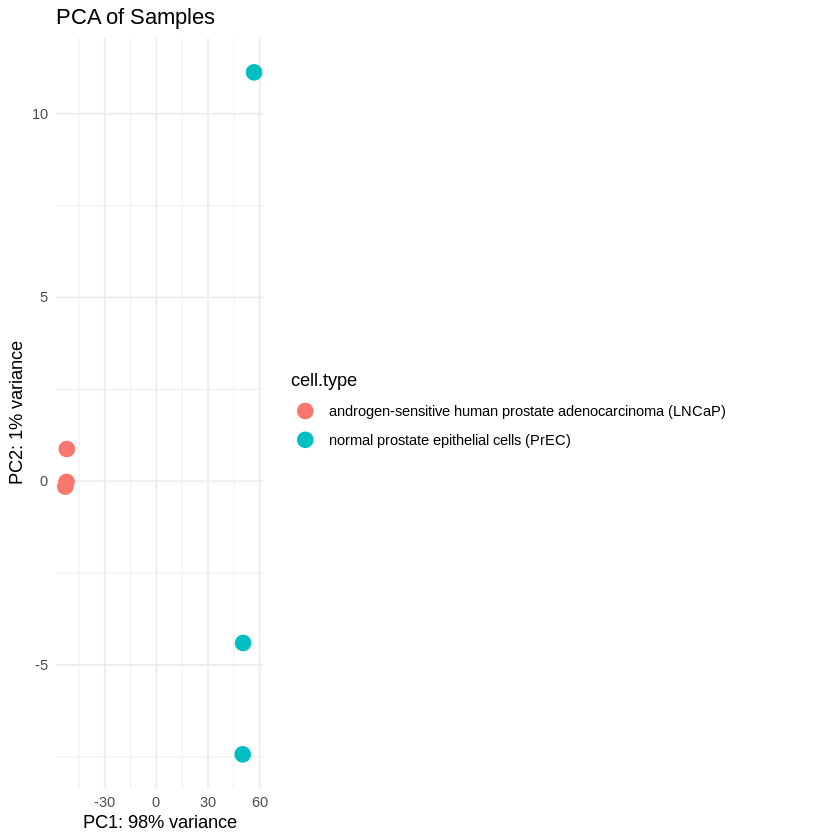

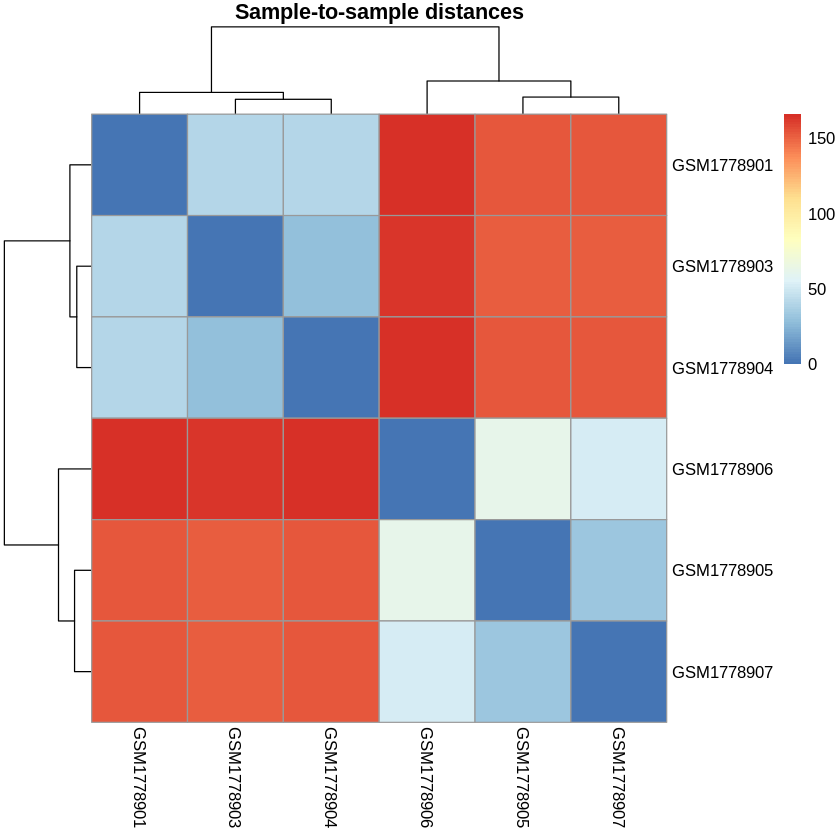

In [161]:
# 정규화
vsd <- vst(dds, blind=FALSE)
# PCA 수행
pcaData <- plotPCA(vsd, intgroup="cell.type", returnData=TRUE)
percentVar <- round(100 * attr(pcaData, "percentVar"))

# PCA 시각화
ggplot(pcaData, aes(PC1, PC2, color=cell.type)) +
  geom_point(size=4) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  ggtitle("PCA of Samples") +
  theme_minimal()

# Hierarchical clustering (sample distance heatmap)
sampleDists <- dist(t(assay(vsd)))
sampleDistMatrix <- as.matrix(sampleDists)
rownames(sampleDistMatrix) <- colnames(vsd)
colnames(sampleDistMatrix) <- colnames(vsd)

pheatmap(sampleDistMatrix,
         clustering_distance_rows = sampleDists,
         clustering_distance_cols = sampleDists,
         main = "Sample-to-sample distances")

## Part 3: Data analysis

```{r part3, eval = FALSE}

  # Run the DESeq2 pipeline (estimate size factors, gene-wise dispersion, fit the model).

  # Extract differential expression analysis results.

  # Define the thresholds (e.g., padj and |log2FC|) and report examples of significantly differentially expressed genes (DEGs).

  # You might want to include comments on the biological meaning / rationale of dispersion estimation and DEG thresholds.

```

In [162]:
dds <- DESeqDataSetFromMatrix(countData = filtered_counts,
                              colData = meta,
                              design = ~ cell.type)  # 분석하고자 하는 변수로 수정

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



In [163]:
# 필터링 후 유전자 수 확인
dds <- dds[rowSums(counts(dds)) >= 10, ]

# DESeq2 분석 실행 (크기 보정, 분산 추정, 모델 적합)
dds <- DESeq(dds)

estimating size factors

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]

final dispersion estimates

fitting model and testing



In [164]:
# 기본 대비군을 기준으로 결과 추출 (예: normal vs cancer)
res <- results(dds, contrast = c("cell.type", "normal prostate epithelial cells (PrEC)", "androgen-sensitive human prostate adenocarcinoma (LNCaP)"))

# 결과 정렬 (padj 기준)
res <- res[order(res$padj), ]

# NA 제거
res <- na.omit(res)

In [165]:
sig_res <- subset(res, padj < 0.05 & abs(log2FoldChange) > 1)

# 상위 10개 유전자 출력
head(sig_res, 10)

log2 fold change (MLE): cell.type normal prostate epithelial cells (PrEC) vs androgen-sensitive human prostate adenocarcinoma (LNCaP) 
Wald test p-value: cell.type normal.prostate.epithelial.cells..PrEC. vs androgen.sensitive.human.prostate.adenocarcinoma..LNCaP. 
DataFrame with 10 rows and 6 columns
        baseMean log2FoldChange     lfcSE      stat       pvalue         padj
       <numeric>      <numeric> <numeric> <numeric>    <numeric>    <numeric>
BIRC8   44402.44       12.15970  0.271517   44.7843  0.00000e+00  0.00000e+00
LGALS1   7055.74        9.67285  0.258527   37.4152 2.21290e-306 1.99449e-302
KRT5    77093.75       13.83208  0.396083   34.9221 3.43026e-267 2.06113e-263
NKX3.1   3963.09       -6.51874  0.187273  -34.8088 1.79312e-265 8.08070e-262
BIRC3    5322.43        9.18389  0.266560   34.4533 4.01506e-260 1.44751e-256
BTBD8    3195.39       -7.98570  0.242750  -32.8968 2.44447e-237 7.34401e-234
SFN     11955.13       10.81929  0.331053   32.6815 2.86334e-234 7.37351e-

In [128]:
# dds <- DESeqDataSetFromMatrix(countData = expr_df,
#                               colData = meta,
#                               design = ~ cell.type, tidy=TRUE)



Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are safe characters
  for column names in R. [This is a message, not a warning or an error]



## Part 4: Visualization

```{r part4, eval = FALSE}

  # Create at least two different plots, including a volcano plot, to visualize and summarize the analysis.


In [168]:
head(dds)

class: DESeqDataSet 
dim: 6 6 
metadata(1): version
assays(4): counts mu H cooks
rownames(6): A1BG A1CF ... A2MP1 A4GALT
rowData names(22): baseMean baseVar ... deviance maxCooks
colnames(6): GSM1778901 GSM1778903 ... GSM1778906 GSM1778907
colData names(5): Sample_geo_accession Sample.Title cell.line cell.type
  sizeFactor

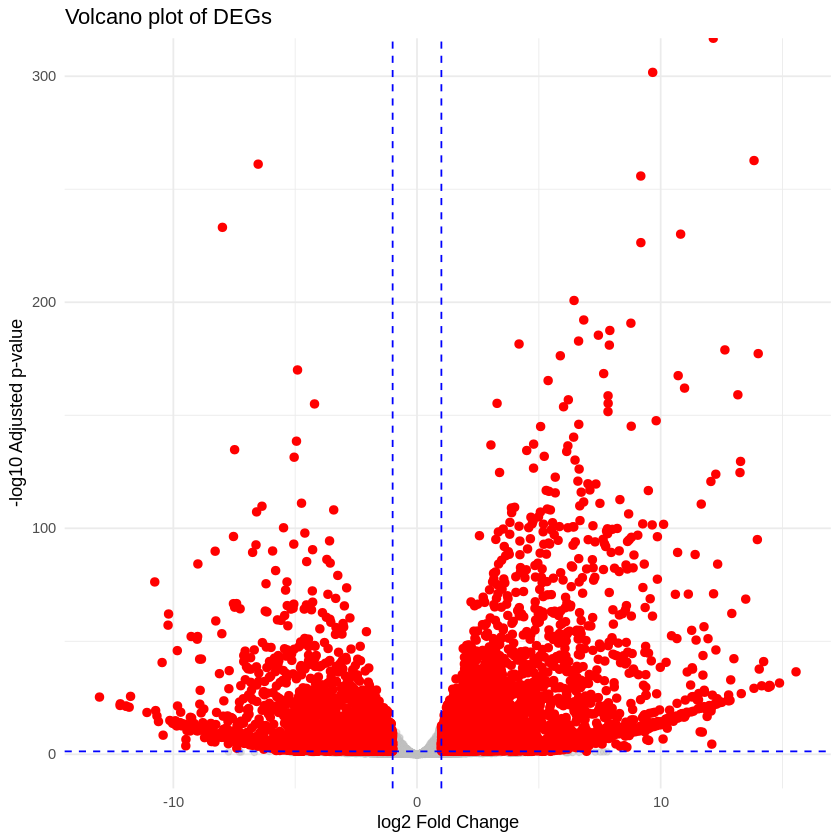

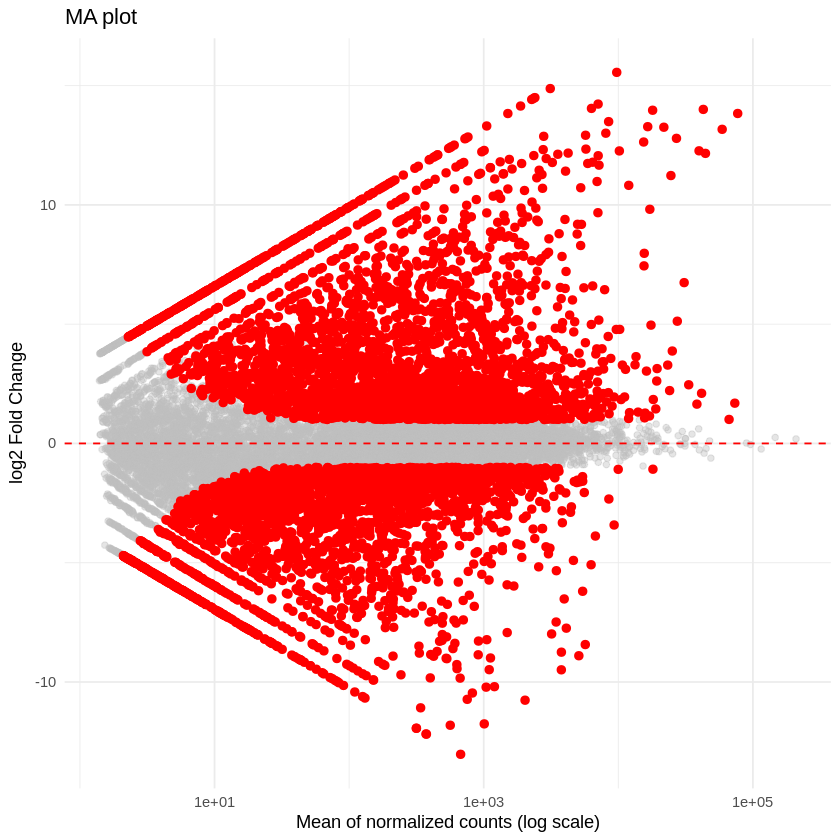

In [170]:
# res는 DESeq2 결과 데이터프레임이라고 가정
res_df <- as.data.frame(res)

# volcano plot 그리기
ggplot(res_df, aes(x = log2FoldChange, y = -log10(padj))) +
  geom_point(alpha=0.4, size=1.5, color = "grey") +
  geom_point(data = subset(res_df, padj < 0.05 & abs(log2FoldChange) > 1),
             aes(x = log2FoldChange, y = -log10(padj)),
             color = "red", size = 2) +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "blue") +
  geom_vline(xintercept = c(-1,1), linetype = "dashed", color = "blue") +
  theme_minimal() +
  labs(title = "Volcano plot of DEGs",
       x = "log2 Fold Change",
       y = "-log10 Adjusted p-value")

# MA plot 그리기
ggplot(res_df, aes(x = baseMean, y = log2FoldChange)) +
  geom_point(alpha=0.4, size=1.5, color = "grey") +
  geom_point(data = subset(res_df, padj < 0.05 & abs(log2FoldChange) > 1),
             aes(x = baseMean, y = log2FoldChange),
             color = "red", size = 2) +
  scale_x_log10() +
  geom_hline(yintercept = 0, color = "red", linetype = "dashed") +
  theme_minimal() +
  labs(title = "MA plot",
       x = "Mean of normalized counts (log scale)",
       y = "log2 Fold Change")

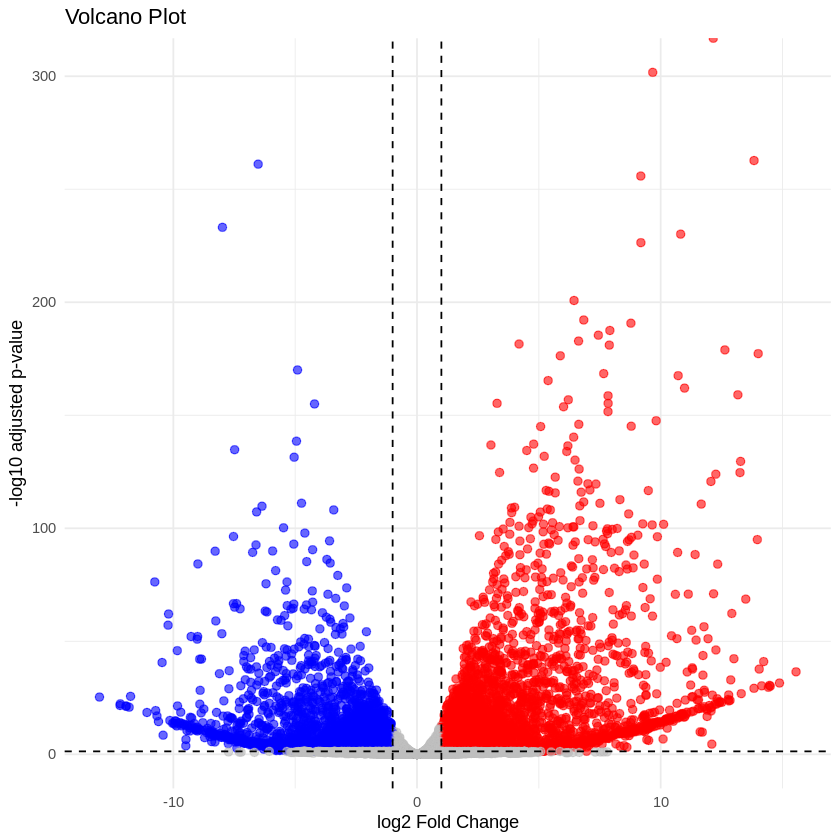

In [171]:
library(ggplot2)

# res가 이미 data.frame 또는 DataFrame 형태라 가정
res_df <- as.data.frame(res)

# NA 제거
res_df <- na.omit(res_df)

# 색상 기준: padj < 0.05 & |log2FoldChange| > 1 인 경우에 색 지정
res_df$color <- "grey"  # 기본 색: 회색
res_df$color[res_df$padj < 0.05 & res_df$log2FoldChange > 1] <- "red"   # upregulated
res_df$color[res_df$padj < 0.05 & res_df$log2FoldChange < -1] <- "blue" # downregulated

# volcano plot 그리기
ggplot(res_df, aes(x = log2FoldChange, y = -log10(padj), color = color)) +
  geom_point(alpha = 0.6, size = 2) +
  scale_color_identity() +  # 색상을 직접 사용
  geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "black") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "black") +
  theme_minimal() +
  labs(title = "Volcano Plot",
       x = "log2 Fold Change",
       y = "-log10 adjusted p-value")


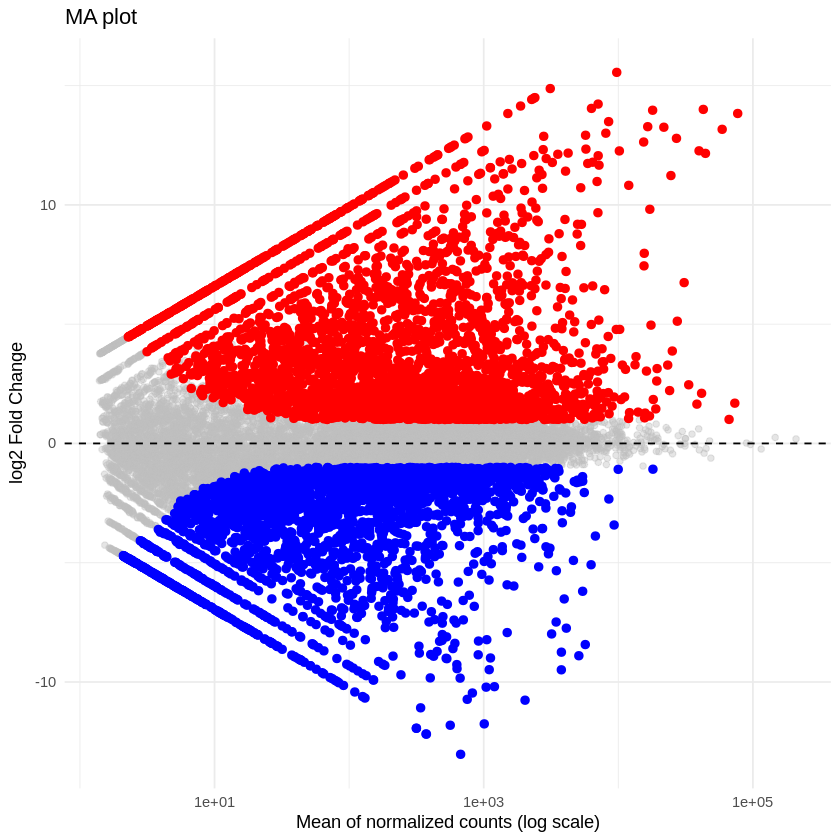

In [172]:
ggplot(res_df, aes(x = baseMean, y = log2FoldChange)) +
  geom_point(alpha = 0.4, size = 1.5, color = "grey") +  # 기본 회색 점들
  geom_point(data = subset(res_df, padj < 0.05 & log2FoldChange > 1),
             aes(x = baseMean, y = log2FoldChange),
             color = "red", size = 2) +  # upregulated 빨강 점
  geom_point(data = subset(res_df, padj < 0.05 & log2FoldChange < -1),
             aes(x = baseMean, y = log2FoldChange),
             color = "blue", size = 2) + # downregulated 파랑 점
  scale_x_log10() +
  geom_hline(yintercept = 0, color = "black", linetype = "dashed") +
  theme_minimal() +
  labs(title = "MA plot",
       x = "Mean of normalized counts (log scale)",
       y = "log2 Fold Change")
